# 03 · Effort study: manual vs assisted

**Question:** does the AI make labelling faster and easier *without making the labels worse*?

## Protocol (do this before running the cells)

1. Start the app on a **separate, empty data folder** so the study is not mixed with practice work:
   `python -m app.server --data eval/studies/data_study`
2. In the app, create exactly these classes: **person, car, bicycle, dog, chair** (delete the starters you do not need).
3. **Manual run:** switch to **Manual**. Upload the 10 images in `eval/data/effort/A`. In each image, outline **every person, car, bicycle, dog and chair bigger than about a thumbnail** (32×32 px) with the **Polygon** tool. Go image by image; do not come back.
4. **Assisted run:** switch to **Assisted**. Upload the 10 images in `eval/data/effort/B` and do the same task using AI outline and suggestions (any detector).
5. Work at a normal, careful pace. Short breaks are fine: gaps over 30 s count as 30 s.

Manual first, then assisted, means any learning effect (getting faster at the task) favours the *manual* run, so a measured saving is, if anything, an underestimate. If a second person is available, have them do it the other way round (A assisted, B manual) to cancel image difficulty too.

## What is measured, per mode
- **seconds per object** and **clicks per object** (from the interaction log; pans and zooms are not counted as work),
- **found**: share of required objects labelled (mask IoU ≥ 0.5 with the true outline),
- **mean IoU** of the found objects: how exact the outlines are,
- **wrong**: labels that match no real object of that class.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "eval" else pathlib.Path.cwd()))
import importlib
from eval import evallib as E
E = importlib.reload(E)   # pick up fixes to evallib without restarting the kernel
E.setup()          # work from the project folder, where the model weights are
print("project folder:", E.ROOT)

project folder: C:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator


In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
# Which study to analyse: "pilot" = first run (random images, data_study),
# "balanced" = class-balanced rerun (notebook 01b, data_study2).
RUN = "balanced"
STUDY = E.ROOT / "eval" / "studies" / ("data_study2" if RUN == "balanced" else "data_study")
coco = E.load_coco()
S = E.load_balanced() if RUN == "balanced" else E.load_subsets()
half_of = {i: "A" for i in S["effort_a"]} | {i: "B" for i in S["effort_b"]}
images, anns, events = E.load_study(STUDY)
print(len(images), "images,", len(anns), "labels,", len(events), "logged events")

loading annotations into memory...
Done (t=0.66s)
creating index...
index created!
20 images, 46 labels, 906 logged events


In [3]:
rows = []
for img in images:
    cid = E.coco_id_from_name(img["name"])
    if cid not in half_of:
        print("skipping (not a study image):", img["name"]); continue
    eff = E.image_effort(events, img["id"])
    sc = E.score_labels(coco, cid, [a for a in anns if a["image_id"] == img["id"]], E.EFFORT_CLASSES)
    rows.append({"image": img["name"], "half": half_of[cid], **eff, **{k: v for k, v in sc.items() if k != "ious"}})
per_image = pd.DataFrame(rows)
# Group by the study CONDITION (half A = manual, half B = assisted), not by the
# mode most clicks were logged in: in the balanced study two assisted images
# had one missed object drawn by hand in Manual mode, which flipped their
# majority mode. That hand-fixing is part of the assisted workflow.
per_image["logged_mode"] = per_image["mode"]
per_image["mode"] = per_image["half"].map({"A": "manual", "B": "assisted"})
per_image.to_csv(E.EVAL / "results" / f"effort_per_image_{RUN}.csv", index=False)
per_image

,image,half,active_s,clicks,keys,panel,actions,mode,undos,ai_accepts,sug_rejects,required,found,extra_optional,wrong,labels,mean_iou
0,coco_000000031620.jpg,A,39.760,88,0,1,89,manual,0,0,0,5,2,0,1,3,0.742361
1,coco_000000047112.jpg,A,23.929,25,0,1,26,manual,0,0,0,3,1,0,0,1,0.736801
2,coco_000000203317.jpg,A,46.714,90,0,1,91,manual,0,0,0,1,1,0,0,1,0.853151
3,coco_000000224051.jpg,A,48.830,110,0,1,111,manual,0,0,0,2,2,1,0,3,0.866736
4,coco_000000305343.jpg,A,17.292,31,0,1,32,manual,0,0,0,1,1,0,0,1,0.910161
5,coco_000000334006.jpg,A,17.142,23,0,1,24,manual,0,0,0,1,1,0,0,1,0.893470
6,coco_000000375278.jpg,A,32.516,60,0,1,61,manual,0,0,0,2,1,0,2,3,0.842492
7,coco_000000395701.jpg,A,28.280,64,0,1,65,manual,0,0,0,1,1,0,1,2,0.901030
8,coco_000000397681.jpg,A,16.633,18,0,1,19,manual,0,0,0,1,1,0,0,1,0.659491
9,coco_000000575243.jpg,A,48.378,86,0,2,88,manual,0,0,0,4,4,0,0,4,0.837377


In [4]:
g = per_image.groupby("mode")
summary = pd.DataFrame({
    "images": g.size(),
    "objects required": g["required"].sum(),
    "objects found": g["found"].sum(),
    "found %": g["found"].sum() / g["required"].sum(),
    "seconds per found object": g["active_s"].sum() / g["found"].sum(),
    "seconds per required object": g["active_s"].sum() / g["required"].sum(),
    "clicks per found object": g["clicks"].sum() / g["found"].sum(),
    "keys per found object": g["keys"].sum() / g["found"].sum(),
    "panel clicks per found object": g["panel"].sum() / g["found"].sum(),
    "all actions per found object": g["actions"].sum() / g["found"].sum(),
    "mean IoU of found objects": (per_image.assign(w=per_image["mean_iou"] * per_image["found"])
                                  .groupby("mode")["w"].sum() / g["found"].sum()),
    "wrong labels": g["wrong"].sum(),
    "undos": g["undos"].sum(),
    "AI accepts": g["ai_accepts"].sum(),
    "suggestions rejected": g["sug_rejects"].sum(),
}).T
summary.round(3)

mode,assisted,manual
images,8.000,12.000
objects required,16.000,25.000
objects found,12.000,19.000
found %,0.750,0.760
seconds per found object,15.848,23.116
seconds per required object,11.886,17.568
clicks per found object,0.000,33.895
keys per found object,0.000,0.000
panel clicks per found object,0.833,0.789
all actions per found object,0.833,34.684


In [5]:
if {"manual", "assisted"} <= set(summary.columns):
    m, a = summary["manual"], summary["assisted"]
    verdict = pd.Series({
        "time saved per object": 1 - a["seconds per found object"] / m["seconds per found object"],
        "speed-up (x faster)": m["seconds per found object"] / a["seconds per found object"],
        "actions saved per object": 1 - a["all actions per found object"] / m["all actions per found object"],
        "speed-up per required object (x)": m["seconds per required object"] / a["seconds per required object"],
        "outline quality change (IoU points)": a["mean IoU of found objects"] - m["mean IoU of found objects"],
        "coverage change (found % points)": a["found %"] - m["found %"],
    }).round(3)
    display(verdict)
else:
    print("need both a manual and an assisted run; modes found:", list(summary.columns))

time saved per object                  0.314
speed-up (x faster)                    1.459
actions saved per object               0.976
speed-up per required object (x)       1.478
outline quality change (IoU points)   -0.082
coverage change (found % points)      -0.010
dtype: float64

### Class by class

Averages over different class mixes can mislead (in the pilot, hard chairs were only in the manual half and pulled its IoU down). This table compares the modes **within each class**.

In [6]:
mode_of = per_image.groupby("half")["mode"].agg(lambda m: m.mode()[0]).to_dict()
pc = pd.DataFrame(E.per_class_scores(coco, images, anns, half_of))
pc["mode"] = pc["half"].map(mode_of)
pc = pc.pivot(index="class", columns="mode", values=["required", "found", "found %", "mean IoU"])
pc.to_csv(E.EVAL / "results" / f"effort_per_class_{RUN}.csv")
pc.round(3)

required           found         found %        mean IoU       
mode    assisted manual assisted manual assisted manual assisted manual
class                                                                  
bicycle      3.0    2.0      3.0    2.0    1.000  1.000    0.871  0.853
car          4.0    5.0      3.0    5.0    0.750  1.000    0.838  0.863
chair        6.0    4.0      4.0    2.0    0.667  0.500    0.690  0.819
dog          3.0    2.0      3.0    1.0    1.000  0.500    0.888  0.910
person       4.0    8.0      3.0    5.0    0.750  0.625    0.664  0.759

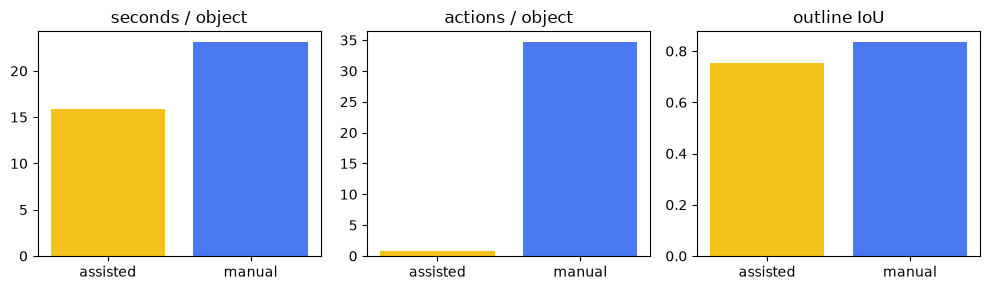

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, (col, title) in zip(axes, [("seconds per found object", "seconds / object"),
                                   ("all actions per found object", "actions / object"),
                                   ("mean IoU of found objects", "outline IoU")]):
    vals = summary.loc[col]
    ax.bar(vals.index, vals.values, color=["#4a78f0" if c == "manual" else "#f4c21b" for c in vals.index])
    ax.set_title(title)
plt.tight_layout(); fig.savefig(E.EVAL / "results" / f"effort_{RUN}.png", dpi=150)

**Reading it honestly:** a real saving shows *less time and fewer clicks per object* with *found % and IoU no worse*. If assisted is faster but IoU drops, the AI trades quality for speed, and that is a finding too. With 10 + 10 images and one person this is a small study: report it as such, and report per-image numbers (above) rather than only the averages.